# Comparing the Three Cheat Detectors

This notebook compares **linear regression**, **logistic regression** and the **neural network** on the seven measurements from the *AI Evaluation and Uncertainty* theme:

| Measurement | Question it answers |
|---|---|
| Accuracy | How often is the model right? |
| Error rate | What kind of mistakes does it make? |
| Completion rate | How often can it give a final verdict without a human? |
| Response time | How fast does it score a kill? |
| Confidence | Can we trust how sure it is? |
| User satisfaction | Do people agree with it? (needs a survey) |
| Cost | How much does it take to train and run? |

**How the test works:** the players are split into 5 groups. Each group takes one turn as the test set while the models train on the other four (5-fold cross-validation). Every player is tested once, by models that never saw them, and each result comes with an error bar showing how much it changed between the 5 rounds. **If two error bars overlap a lot, the difference may just be luck.**

Needs `data/kill_features.csv` (from `build_dataset_hf.py` or `build_dataset.py`). Takes about a minute. Every chart is also saved to `results/figures/` for your slides or poster.

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = "data/kill_features.csv"
K_FOLDS = 5
MIN_KILLS = 5            # players with fewer kills always go to a human
REVIEW_MARGIN = 0.10     # a player's average this close to the cut-off goes to a human
FIG_DIR = "results/figures"
os.makedirs(FIG_DIR, exist_ok=True)

MODELS = ["Linear regression", "Logistic regression", "Neural network"]
COLORS = {"Linear regression": "#2a78d6", "Logistic regression": "#eb6834", "Neural network": "#1baf7a"}
NEUTRAL = "#8a8984"       # for the baselines, which aren't models
INK, INK_2, SURFACE, GRID = "#0b0b0b", "#52514e", "#fcfcfb", "#e4e3df"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.titlecolor": INK, "axes.titlelocation": "left", "axes.titlepad": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK_2, "ytick.color": INK_2, "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": False, "legend.labelcolor": INK, "font.size": 11, "lines.linewidth": 2,
})

df = pd.read_csv(DATA_PATH, dtype={"steamid": str})
print("kills:", len(df), " players:", df["steamid"].nunique(),
      " cheaters:", df.loc[df["is_cheater"] == 1, "steamid"].nunique())

kills: 20295  players: 1776  cheaters: 466


## The models
The same features, preparation and training as `three_simple_models.ipynb`, so the results match that notebook.

In [2]:
FEATURES = [
    "head_ang_err", "head_miss_units", "chest_ang_err", "spatial_dist_to_target",
    "on_head_at_kill", "headshot",
    "ms_on_target", "approach_peak_ang_vel", "acquired_from_deg",
    "mean_ang_vel", "max_ang_vel", "max_abs_jerk", "frac_window_on_head",
    "head_err_last_half_s", "ang_vel_std_last_half_s", "head_err_early",
]
FEATURES = [f for f in FEATURES if f in df.columns]
LOG = {"head_ang_err", "head_miss_units", "chest_ang_err", "spatial_dist_to_target",
       "ms_on_target", "approach_peak_ang_vel", "acquired_from_deg", "mean_ang_vel",
       "max_ang_vel", "max_abs_jerk", "head_err_last_half_s", "ang_vel_std_last_half_s",
       "head_err_early"}


def to_matrix(part):
    X = part[FEATURES].astype(float).to_numpy()
    for j, f in enumerate(FEATURES):
        if f in LOG:
            X[:, j] = np.log1p(np.clip(X[:, j], 0, None))
    return X


def fit_prep(train_part):
    M = to_matrix(train_part)
    with np.errstate(all="ignore"):
        median = np.nanmedian(M, axis=0)
    median = np.where(np.isnan(median), 0, median)
    M = np.where(np.isnan(M), median, M)
    std = M.std(axis=0)
    std[std == 0] = 1
    return {"median": median, "mean": M.mean(axis=0), "std": std}


def apply_prep(part, prep):
    M = to_matrix(part)
    return (np.where(np.isnan(M), prep["median"], M) - prep["mean"]) / prep["std"]


def kill_weights(y):
    n_pos = y.sum(); n_neg = len(y) - n_pos
    sw = np.where(y == 1, len(y) / (2 * n_pos), len(y) / (2 * n_neg))
    return sw / sw.mean()


def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))


def relu(z):
    return np.maximum(0, z)


def train_linear(X, y, sw, lr=0.01, epochs=2000):
    n, k = X.shape; w, b = np.zeros(k), 0.0
    for _ in range(epochs):
        error = X @ w + b - y
        w -= lr * 2 * X.T @ (sw * error) / n
        b -= lr * 2 * np.mean(sw * error)
    return {"type": "linear", "w": w, "b": b}


def train_logistic(X, y, sw, lr=0.1, epochs=2000):
    n, k = X.shape; w, b = np.zeros(k), 0.0
    for _ in range(epochs):
        p = sigmoid(X @ w + b)
        w -= lr * X.T @ (sw * (p - y)) / n
        b -= lr * np.mean(sw * (p - y))
    return {"type": "logistic", "w": w, "b": b}


def train_network(X, y, sw, hidden=8, lr=0.1, epochs=2000, seed=0):
    n, k = X.shape; r = np.random.default_rng(seed)
    W1 = r.normal(0, np.sqrt(2 / k), size=(k, hidden)); b1 = np.zeros(hidden)
    w2 = r.normal(0, np.sqrt(2 / hidden), size=hidden); b2 = 0.0
    for _ in range(epochs):
        Z1 = X @ W1 + b1; A1 = relu(Z1); p = sigmoid(A1 @ w2 + b2)
        d_out = sw * (p - y) / n
        d_hidden = np.outer(d_out, w2) * (Z1 > 0)
        W1 -= lr * X.T @ d_hidden; b1 -= lr * d_hidden.sum(axis=0)
        w2 -= lr * A1.T @ d_out; b2 -= lr * d_out.sum()
    return {"type": "network", "W1": W1, "b1": b1, "w2": w2, "b2": b2}


def predict(model, X):
    """Score per kill, kept between 0 and 1 (linear regression can go outside that range)."""
    if model["type"] == "linear":
        return np.clip(X @ model["w"] + model["b"], 0, 1)
    if model["type"] == "logistic":
        return sigmoid(X @ model["w"] + model["b"])
    return sigmoid(relu(X @ model["W1"] + model["b1"]) @ model["w2"] + model["b2"])


def n_parameters(model):
    return sum(np.size(v) for k, v in model.items() if k != "type")


TRAINERS = dict(zip(MODELS, [train_linear, train_logistic, train_network]))


def kill_metrics(y, pred):
    tp = np.sum((pred == 1) & (y == 1)); fp = np.sum((pred == 1) & (y == 0))
    fn = np.sum((pred == 0) & (y == 1)); tn = np.sum((pred == 0) & (y == 0))
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    return {"accuracy": (tp + tn) / len(y), "error_rate": (fp + fn) / len(y),
            "precision": precision, "recall": recall,
            "f1": 2 * precision * recall / (precision + recall) if precision + recall else 0.0,
            "false_flag_rate": fp / (fp + tn) if fp + tn else 0.0,
            "miss_rate": fn / (fn + tp) if fn + tp else 0.0}


def pick_threshold(scores, y):
    candidates = np.quantile(scores, np.linspace(0.05, 0.95, 37))
    return float(max(candidates, key=lambda t: kill_metrics(y, (scores >= t).astype(int))["f1"]))


def split_players(part, frac, seed):
    """Pick a share of players (cheaters and clean players separately) for a held-out group."""
    players = part.groupby("steamid")["is_cheater"].max()
    rng = np.random.default_rng(seed)
    held = []
    for label in [0, 1]:
        ids = players[players == label].index.to_numpy()
        rng.shuffle(ids)
        held += list(ids[:max(1, round(frac * len(ids)))])
    return set(held)

## Run the test
For each of the 5 rounds: train all three models on 4 groups of players (holding back a quarter of them to choose each model's cut-off), then score the 5th group. Training time, scoring time and model size are measured at the same time.

In [3]:
players = df.groupby("steamid")["is_cheater"].max()
if players.sum() < K_FOLDS:
    raise SystemExit(f"Need at least {K_FOLDS} cheaters for {K_FOLDS}-fold testing (found {players.sum()}).")

rng = np.random.default_rng(0)
fold_of = {}
for label in [1, 0]:                                   # spread cheaters evenly over the folds
    ids = players[players == label].index.to_numpy()
    rng.shuffle(ids)
    for i, sid in enumerate(ids):
        fold_of[sid] = i % K_FOLDS
df["fold"] = df["steamid"].map(fold_of)

oof_parts, fold_rows = [], []
for fold in range(K_FOLDS):
    test = df[df["fold"] == fold]
    rest = df[df["fold"] != fold]
    val_ids = split_players(rest, 0.25, seed=fold)
    train, val = rest[~rest["steamid"].isin(val_ids)], rest[rest["steamid"].isin(val_ids)]

    prep = fit_prep(train)
    X_tr, X_va, X_te = apply_prep(train, prep), apply_prep(val, prep), apply_prep(test, prep)
    y_tr, y_va, y_te = (p["is_cheater"].to_numpy().astype(float) for p in (train, val, test))
    sw = kill_weights(y_tr)

    for name in MODELS:
        t0 = time.perf_counter()
        model = TRAINERS[name](X_tr, y_tr, sw)
        train_seconds = time.perf_counter() - t0
        threshold = pick_threshold(predict(model, X_va), y_va)

        t0 = time.perf_counter()
        for _ in range(50):
            p_te = predict(model, X_te)
        us_per_kill = (time.perf_counter() - t0) / 50 / len(X_te) * 1e6

        fold_rows.append({"model": name, "fold": fold, "train_seconds": train_seconds,
                          "us_per_kill": us_per_kill, "parameters": n_parameters(model),
                          "threshold": threshold,
                          **kill_metrics(y_te, (p_te >= threshold).astype(int))})
        oof_parts.append(pd.DataFrame({"model": name, "fold": fold, "steamid": test["steamid"].to_numpy(),
                                       "y": y_te, "p": p_te, "threshold": threshold}))
    print(f"round {fold + 1}/{K_FOLDS} done")

folds = pd.DataFrame(fold_rows)
oof = pd.concat(oof_parts, ignore_index=True)
# "Always say clean" baseline, per fold
baseline_acc = df.groupby("fold")["is_cheater"].apply(lambda s: 1 - s.mean())

round 1/5 done
round 2/5 done
round 3/5 done
round 4/5 done
round 5/5 done


### Chart helpers

In [4]:
def bar_group(ax, metrics, labels, fmt="{:.0%}", models=MODELS, extra=None):
    """Grouped bars: one group per metric, one bar per model, mean with an error bar (std over folds).
    extra = optional {"label": ..., "values": {metric: (mean, std)}} drawn as a neutral bar."""
    entities = list(models) + ([extra["label"]] if extra else [])
    width = 0.8 / len(entities)
    x = np.arange(len(metrics))
    for i, ent in enumerate(entities):
        if extra and ent == extra["label"]:
            means = [extra["values"][m][0] for m in metrics]; stds = [extra["values"][m][1] for m in metrics]
            color = NEUTRAL
        else:
            g = folds[folds["model"] == ent]
            means = [g[m].mean() for m in metrics]; stds = [g[m].std() for m in metrics]
            color = COLORS[ent]
        pos = x + (i - (len(entities) - 1) / 2) * width
        ax.bar(pos, means, width * 0.92, yerr=stds, color=color, label=ent,
               error_kw={"ecolor": INK_2, "elinewidth": 1.2, "capsize": 3})
        for xi, m, s in zip(pos, means, stds):
            ax.text(xi, m + (s if np.isfinite(s) else 0) + 0.015 * ax.get_ylim()[1], fmt.format(m),
                    ha="center", va="bottom", fontsize=9, color=INK)
    ax.set_xticks(x, labels)


def save(fig, name):
    fig.tight_layout()
    fig.savefig(f"{FIG_DIR}/{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

## 1. Accuracy
**Left:** share of test kills classified correctly. The grey bar always says "clean"; because most kills are clean it scores well while catching **zero** cheaters, which is why accuracy alone isn't enough.
**Right:** precision (of the kills flagged, how many were cheaters), recall (of the cheater kills, how many were caught) and F1 (the balance of the two).

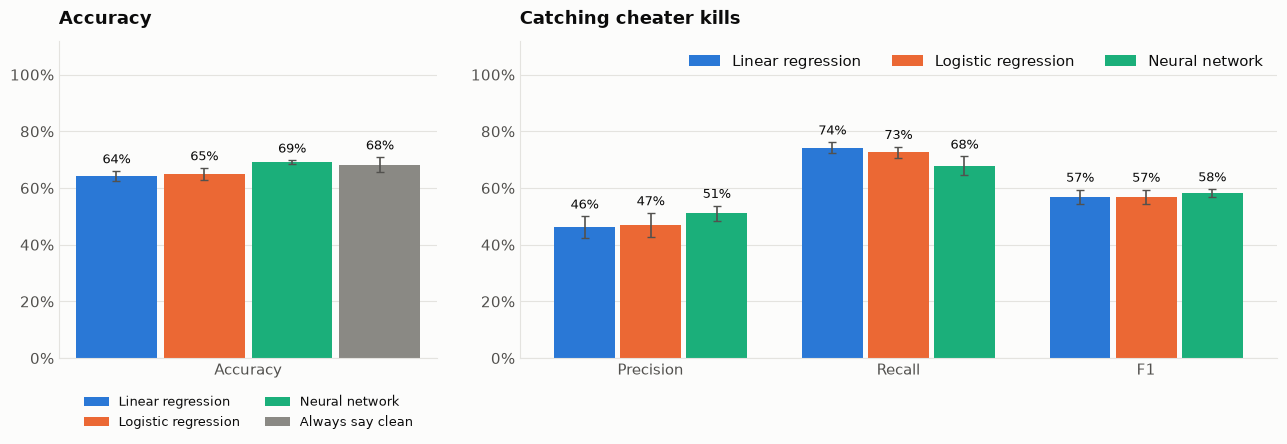

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 2]})
ax = axes[0]; ax.set_ylim(0, 1.12)
bar_group(ax, ["accuracy"], ["Accuracy"],
          extra={"label": "Always say clean", "values": {"accuracy": (baseline_acc.mean(), baseline_acc.std())}})
ax.set_title("Accuracy"); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2, fontsize=9)
ax = axes[1]; ax.set_ylim(0, 1.12)
bar_group(ax, ["precision", "recall", "f1"], ["Precision", "Recall", "F1"])
ax.set_title("Catching cheater kills"); ax.legend(loc="upper right", ncol=3)
for ax in axes:
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
save(fig, "1_accuracy")

## 2. Error rate
All mistakes, split into the two kinds. A **false flag** accuses an innocent player, the most harmful mistake. A **miss** lets a cheater kill through.

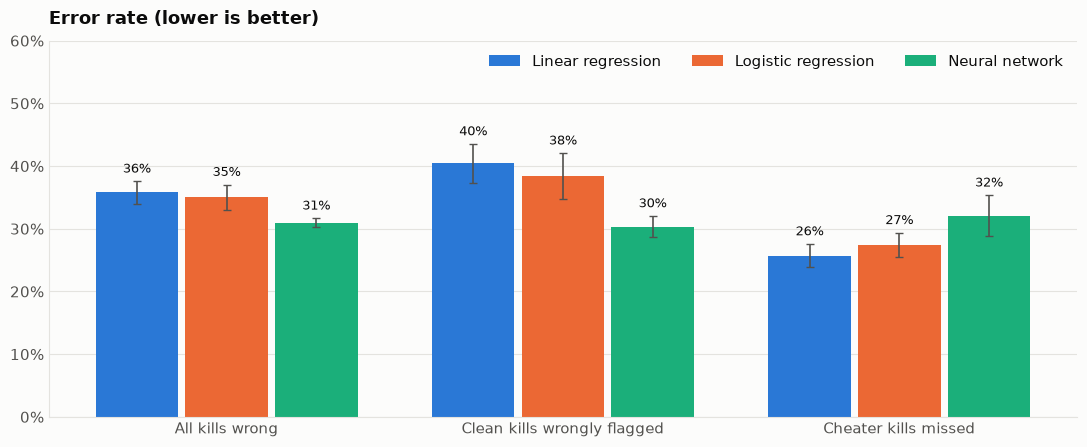

In [6]:
fig, ax = plt.subplots(figsize=(11, 4.6)); ax.set_ylim(0, max(0.6, folds[["error_rate", "false_flag_rate", "miss_rate"]].max().max() * 1.25))
bar_group(ax, ["error_rate", "false_flag_rate", "miss_rate"],
          ["All kills wrong", "Clean kills wrongly flagged", "Cheater kills missed"])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Error rate (lower is better)"); ax.legend(loc="upper right", ncol=3)
save(fig, "2_error_rate")

## 3. Completion rate
How often the system can give a **player** a final verdict without a human.
- **One model alone:** a player gets a verdict if they have at least 5 kills and their average score is clearly above or below the model's cut-off (more than 0.10 away). Otherwise a human decides.
- **All three must agree:** the rule used in `cheat_app.py`. A verdict only when all three models land on the same side of their cut-offs.

**Verdict accuracy** is how often those final verdicts were right. A system that decides less often but is right more often is the "human in the loop" trade-off.

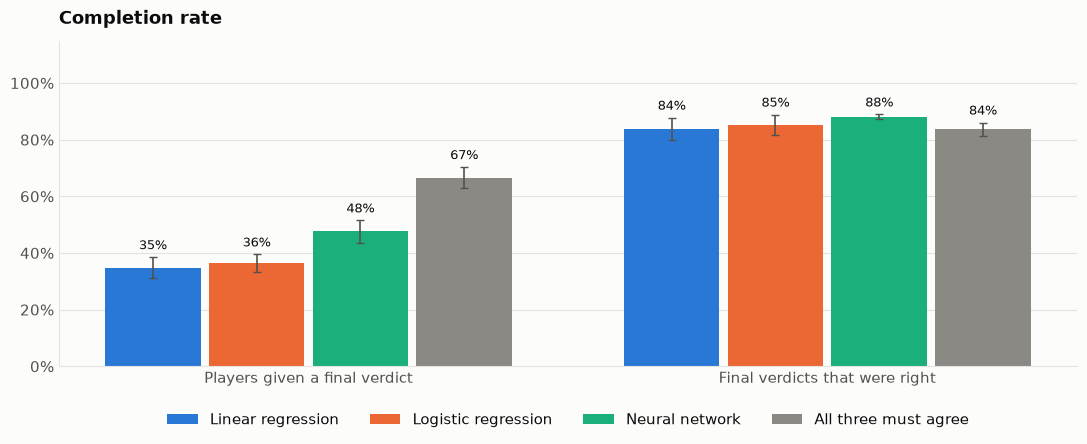

In [7]:
player_avg = oof.groupby(["model", "fold", "steamid"]).agg(avg=("p", "mean"), kills=("p", "size"),
                                                          y=("y", "max"), threshold=("threshold", "first")).reset_index()
rows = []
for (name, fold), g in player_avg.groupby(["model", "fold"]):
    decided = (g["kills"] >= MIN_KILLS) & ((g["avg"] - g["threshold"]).abs() >= REVIEW_MARGIN)
    correct = (g["avg"] >= g["threshold"]).astype(int) == g["y"]
    rows.append({"model": name, "fold": fold, "completion": decided.mean(),
                 "verdict_accuracy": correct[decided].mean() if decided.any() else np.nan})
wide = player_avg.assign(flag=player_avg["avg"] >= player_avg["threshold"]) \
                 .pivot_table(index=["fold", "steamid"], columns="model", values="flag", aggfunc="first")
info = player_avg[player_avg["model"] == MODELS[0]].set_index(["fold", "steamid"])[["kills", "y"]]
wide = wide.join(info)
wide["n_flag"] = wide[MODELS].sum(axis=1)
for fold, g in wide.groupby(level="fold"):
    decided = (g["kills"] >= MIN_KILLS) & g["n_flag"].isin([0, len(MODELS)])
    correct = (g["n_flag"] == len(MODELS)).astype(int) == g["y"]
    rows.append({"model": "All three must agree", "fold": fold, "completion": decided.mean(),
                 "verdict_accuracy": correct[decided].mean() if decided.any() else np.nan})
completion = pd.DataFrame(rows)
for name in MODELS:      # add to the per-fold table so the summary includes it
    sub = completion[completion["model"] == name].set_index("fold")
    folds.loc[folds["model"] == name, "completion"] = folds.loc[folds["model"] == name, "fold"].map(sub["completion"])
    folds.loc[folds["model"] == name, "verdict_accuracy"] = folds.loc[folds["model"] == name, "fold"].map(sub["verdict_accuracy"])

agree = completion[completion["model"] == "All three must agree"]
fig, ax = plt.subplots(figsize=(11, 4.6)); ax.set_ylim(0, 1.15)
bar_group(ax, ["completion", "verdict_accuracy"], ["Players given a final verdict", "Final verdicts that were right"],
          extra={"label": "All three must agree",
                 "values": {m: (agree[m].mean(), agree[m].std()) for m in ["completion", "verdict_accuracy"]}})
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Completion rate"); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=4)
save(fig, "3_completion_rate")

## 4. Response time
Time to score one kill once the model is trained. All three are effectively instant. In practice the wait comes from **reading the demo file** (about a minute for a full match in `cheat_app.py`), not from the models.

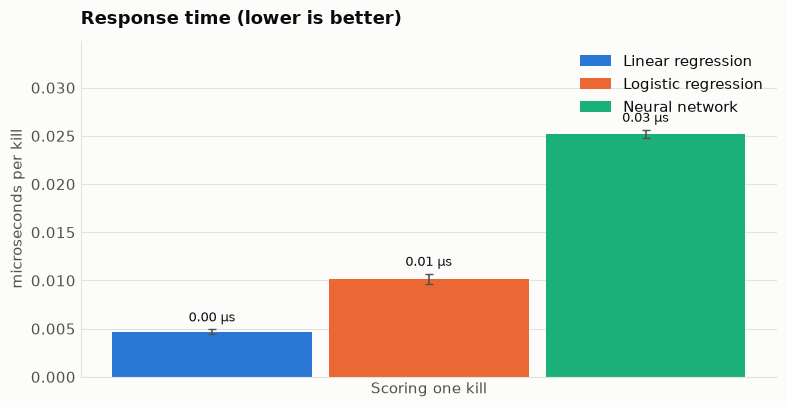

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.set_ylim(0, folds["us_per_kill"].max() * 1.35)
bar_group(ax, ["us_per_kill"], ["Scoring one kill"], fmt="{:.2f} µs")
ax.set_ylabel("microseconds per kill"); ax.set_title("Response time (lower is better)")
ax.legend(loc="upper right")
save(fig, "4_response_time")

## 5. Confidence
**Left:** how sure each model is on average (50% = coin flip, 100% = certain).
**Middle:** Brier score, the average gap between the score and the truth; lower means the confidence is better earned.
**Right:** calibration. When a model gives a kill a score of 80%, are about 80% of those kills really by cheaters? Points **below** the dashed line mean the model is over-confident about cheating. Expect this here: cheater kills were weighted more during training, which pushes scores up.

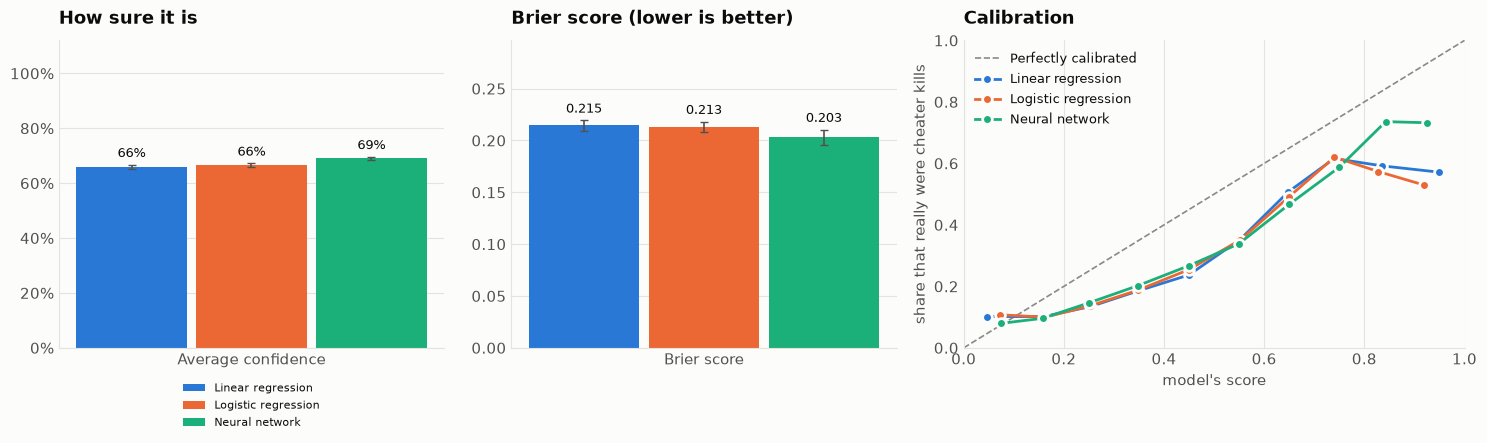

In [9]:
conf = oof.assign(confidence=np.maximum(oof["p"], 1 - oof["p"]), brier=(oof["p"] - oof["y"]) ** 2) \
          .groupby(["model", "fold"])[["confidence", "brier"]].mean().reset_index()
folds = folds.drop(columns=["confidence", "brier"], errors="ignore").merge(conf, on=["model", "fold"])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1, 1, 1.3]})
ax = axes[0]; ax.set_ylim(0, 1.12)
bar_group(ax, ["confidence"], ["Average confidence"])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); ax.set_title("How sure it is")
ax = axes[1]; ax.set_ylim(0, folds["brier"].max() * 1.35)
bar_group(ax, ["brier"], ["Brier score"], fmt="{:.3f}"); ax.set_title("Brier score (lower is better)")
ax = axes[2]
ax.plot([0, 1], [0, 1], ls="--", lw=1.2, color=NEUTRAL, label="Perfectly calibrated")
for name in MODELS:
    s = oof[oof["model"] == name]
    bins = np.minimum((s["p"] * 10).astype(int), 9)
    curve = s.groupby(bins).agg(score=("p", "mean"), actual=("y", "mean"), n=("y", "size"))
    curve = curve[curve["n"] >= 10]                                   # skip nearly empty bins
    ax.plot(curve["score"], curve["actual"], marker="o", ms=7, color=COLORS[name], label=name,
            markeredgecolor=SURFACE, markeredgewidth=2)
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.grid(axis="both")
ax.set_xlabel("model's score"); ax.set_ylabel("share that really were cheater kills")
ax.set_title("Calibration"); ax.legend(loc="upper left", fontsize=9)
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), fontsize=8)
save(fig, "5_confidence")

### Confidence and accuracy together
If a model only answers for the kills it's most confident about and passes the rest to a human, how accurate are the answers it does give? A line that rises steeply as coverage drops means **confidence is a useful signal for when to call in a human**.

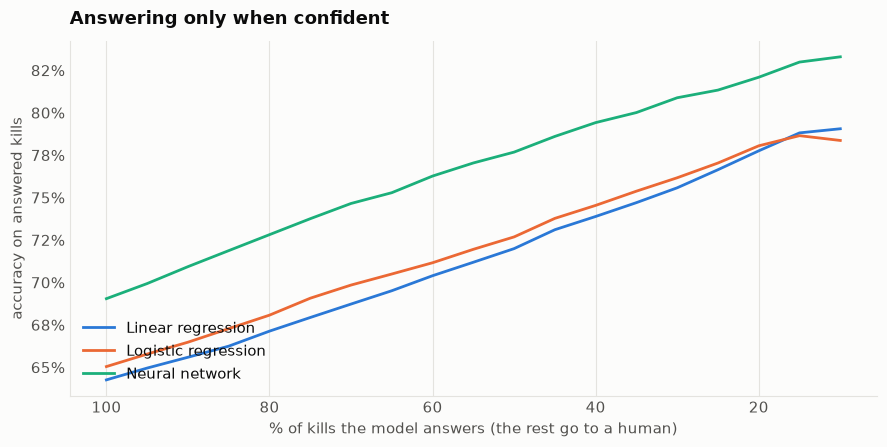

In [10]:
coverages = np.linspace(0.1, 1.0, 19)
fig, ax = plt.subplots(figsize=(9, 4.6))
for name in MODELS:
    s = oof[oof["model"] == name]
    certainty = (s["p"] - s["threshold"]).abs().to_numpy()
    correct = ((s["p"] >= s["threshold"]).astype(int) == s["y"]).to_numpy()
    order = np.argsort(-certainty)
    acc = [correct[order[:max(1, int(c * len(order)))]].mean() for c in coverages]
    ax.plot(coverages * 100, acc, color=COLORS[name], label=name)
ax.invert_xaxis(); ax.grid(axis="both")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("% of kills the model answers (the rest go to a human)"); ax.set_ylabel("accuracy on answered kills")
ax.set_title("Answering only when confident"); ax.legend(loc="lower left")
save(fig, "5b_accuracy_vs_coverage")

## 6. Cost
**Left:** time to train once on a normal laptop (no GPU, no cloud, no paid tools). **Right:** how many numbers each model has to learn and store. Two separate charts because seconds and counts don't share a scale.

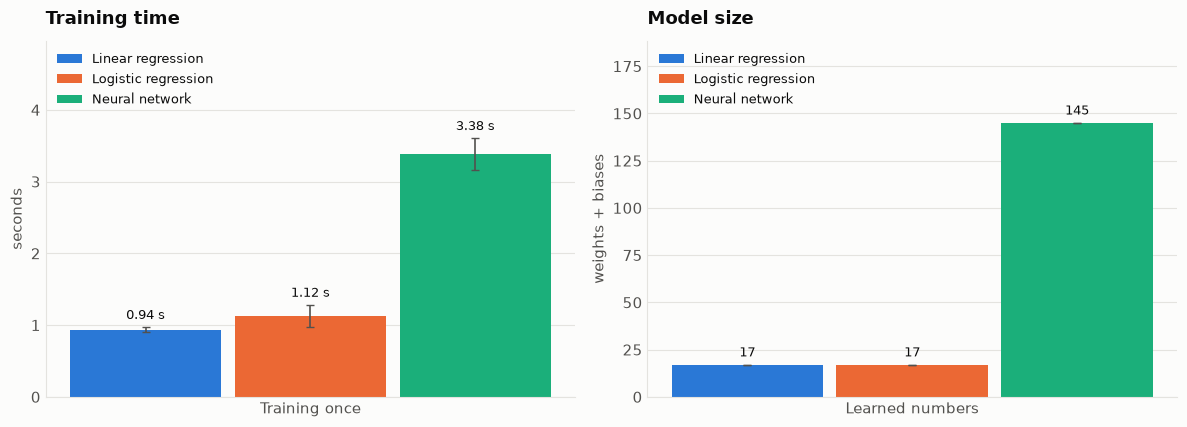

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
ax = axes[0]; ax.set_ylim(0, folds["train_seconds"].max() * 1.35)
bar_group(ax, ["train_seconds"], ["Training once"], fmt="{:.2f} s")
ax.set_ylabel("seconds"); ax.set_title("Training time")
ax = axes[1]; ax.set_ylim(0, folds["parameters"].max() * 1.3)
bar_group(ax, ["parameters"], ["Learned numbers"], fmt="{:.0f}")
ax.set_ylabel("weights + biases"); ax.set_title("Model size")
for ax in axes:
    ax.legend(loc="upper left", fontsize=9)
save(fig, "6_cost")

## 7. User satisfaction
This can't come from the demo data; it needs people. Suggested survey:
1. Pick about 10 players the models scored (some flagged, some cleared) and show a few CS2 players their most suspicious kills from `cheat_app.py`, **without** the verdicts.
2. Ask: "Cheating or not?" and "How confident are you (1–5)?"
3. Show each model's verdict and ask: "How much do you agree with this verdict (1–5)?"

Type each person's agreement ratings into `SURVEY` below and re-run this cell to get the chart.

In [12]:
SURVEY = {
    # One rating (1-5) per person per verdict shown, for example:
    # "Linear regression":   [3, 4, 2, 3, 4],
    # "Logistic regression": [3, 4, 3, 3, 4],
    # "Neural network":      [4, 5, 4, 4, 5],
}
if not any(SURVEY.values()):
    print("No survey answers yet. Fill in SURVEY above and re-run this cell.")
else:
    fig, ax = plt.subplots(figsize=(8, 4.4))
    for i, name in enumerate(MODELS):
        ratings = np.array(SURVEY.get(name, []), dtype=float)
        if len(ratings) == 0:
            continue
        ax.bar(i, ratings.mean(), 0.6, yerr=ratings.std(), color=COLORS[name], label=name,
               error_kw={"ecolor": INK_2, "elinewidth": 1.2, "capsize": 3})
        ax.scatter(np.full(len(ratings), i) + np.linspace(-0.15, 0.15, len(ratings)), ratings,
                   s=40, color=INK, alpha=0.6, zorder=3, edgecolor=SURFACE, linewidth=1.5)
        ax.text(i, 5.25, f"{ratings.mean():.1f} avg  (n={len(ratings)})", ha="center", fontsize=9, color=INK)
    ax.set_xticks(range(len(MODELS)), MODELS); ax.set_ylim(0, 5.6); ax.set_yticks([1, 2, 3, 4, 5])
    ax.set_ylabel("agreement (1 = disagree, 5 = agree)"); ax.set_title("User satisfaction")
    save(fig, "7_user_satisfaction")

No survey answers yet. Fill in SURVEY above and re-run this cell.


## Summary table
Mean ± standard deviation across the 5 rounds. Saved to `results/model_comparison.csv`.

In [13]:
summary_cols = {
    "accuracy": "Accuracy", "error_rate": "Error rate", "false_flag_rate": "False flag rate",
    "miss_rate": "Miss rate", "f1": "F1", "completion": "Completion rate",
    "verdict_accuracy": "Verdict accuracy", "confidence": "Avg confidence", "brier": "Brier score",
    "us_per_kill": "µs per kill", "train_seconds": "Training seconds", "parameters": "Parameters",
}
g = folds.groupby("model")
summary = pd.DataFrame({label: g[col].mean().round(3).astype(str) + " ± " + g[col].std().round(3).astype(str)
                        for col, label in summary_cols.items()}).loc[MODELS]
summary["Parameters"] = g["parameters"].first().loc[MODELS].astype(int).astype(str)
summary.T.to_csv("results/model_comparison.csv")
print(f"Figures saved to {FIG_DIR}/")
summary.T

Figures saved to results/figures/


model,Linear regression,Logistic regression,Neural network
Accuracy,0.642 ± 0.018,0.65 ± 0.02,0.69 ± 0.007
Error rate,0.358 ± 0.018,0.35 ± 0.02,0.31 ± 0.007
False flag rate,0.404 ± 0.031,0.384 ± 0.036,0.304 ± 0.017
Miss rate,0.257 ± 0.019,0.274 ± 0.02,0.321 ± 0.032
F1,0.568 ± 0.026,0.568 ± 0.026,0.582 ± 0.015
Completion rate,0.348 ± 0.037,0.363 ± 0.032,0.476 ± 0.039
Verdict accuracy,0.839 ± 0.039,0.853 ± 0.035,0.881 ± 0.009
Avg confidence,0.66 ± 0.008,0.665 ± 0.008,0.691 ± 0.006
Brier score,0.215 ± 0.005,0.213 ± 0.005,0.203 ± 0.007
µs per kill,0.005 ± 0.0,0.01 ± 0.001,0.025 ± 0.0
